In [1]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import random
import os
import torch
from torch import nn
from torch.nn import functional as F
from collections import deque

In [2]:
# Note: to learn more about the env please check 01 notebook
# Same Q-learning as 04 notebook, but instead of a Q table we use a neural net
# the net takes the state as input and outputs Q value for every action
# two tricks to keep training stable:
# experience replay (replay memory): save transitions and learn from random old ones, not only the last step
# target network: a copy of the net that is updated less often, used for the TD target

In [3]:
# Deep Q Network implementation
class DQN(nn.Module):
    def __init__(self, num_states, num_actions) -> None:
        super().__init__()
        self.fc1 = nn.Linear(num_states, 32)
        self.out = nn.Linear(32, num_actions)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        return self.out(x)

# memory for experience replay
class ReplayMemory():
    def __init__(self, maxlen):
        self.memory = deque([], maxlen=maxlen)

    def append(self, transition):
        self.memory.append(transition)

    def sample(self, sample_size):
        return random.sample(self.memory, sample_size)

    def __len__(self):
        return len(self.memory)

# state is a number from 0 to 15, net input is one hot vector of size 16
def state_to_dqn_input(state):
    input = torch.zeros(16)
    input[state] = 1
    return input

# epsilon greedy action selection
def epsilon_greedy_action(state, policy_dqn, env, epsilon):
    if random.uniform(0, 1) < epsilon: # explore
        return env.action_space.sample()

    else:
        with torch.no_grad():
            dqn_input = state_to_dqn_input(state)
            q_values = policy_dqn(dqn_input)
        return q_values.argmax().item() # choose greedy

# one training step of the policy net on a batch from memory
def optimize(discount_factor_g, batch, policy_dqn, target_dqn, loss_fn, optimizer):

    states = torch.stack([state_to_dqn_input(s) for s, a, ns, r, t in batch])
    actions = torch.tensor([a for s, a, ns, r, t in batch], dtype=torch.int64).unsqueeze(-1)
    next_states = torch.stack([state_to_dqn_input(ns) for s, a, ns, r, t in batch])
    rewards = torch.tensor([r for s, a, ns, r, t in batch], dtype=torch.float32)
    terminated_flags = torch.tensor([t for s, a, ns, r, t in batch], dtype=torch.float32)

    # Q(S, A) for the current state and the actions that were taken from that state
    current_q_values = policy_dqn(states).gather(1, actions).squeeze(-1)

    with torch.no_grad(): # gradients are not needed for the target_dqn as updating only policy_dqn
        # max Q value for the next state from the target net
        next_q_values = target_dqn(next_states).max(1).values
        # the value of a terminal state is 0
        next_q_values[terminated_flags == 1] = 0.0

        # 1 step TD target = reward + gamma * max_a Q_target(S', a)
        target_q_values = rewards + (discount_factor_g * next_q_values)

    loss = loss_fn(current_q_values, target_q_values)

    # learn
    optimizer.zero_grad()
    loss.backward()
    torch.nn.utils.clip_grad_norm_(policy_dqn.parameters(), max_norm=1.0)
    optimizer.step()

In [4]:
# Deep Q-learning
env = gym.make("FrozenLake-v1", is_slippery=True, render_mode=None)

# env parameters
num_states = env.observation_space.n
num_actions = env.action_space.n

# hyperparameters
num_episodes = 10000 # num of epi to train
discount_factor_g = 0.99

# epsilon decay rate for random exploration
epsilon_start = 1.0 # 100% exploration
epsilon_end = 0.01 # some exploration at the end
epsilon_decay_episodes = num_episodes * 0.8 # epsilon reaches epsilon_end at 80% of episodes
epsilon_decay = (epsilon_start - epsilon_end) / epsilon_decay_episodes

# policy and target dqn
policy_dqn = DQN(num_states=num_states, num_actions=num_actions)
target_dqn = DQN(num_states=num_states, num_actions=num_actions)
# make target_dqn same as policy_dqn when starting
target_dqn.load_state_dict(policy_dqn.state_dict())

# DQN neural net parameters
batch_size = 256
learning_rate_a = 0.0001
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(policy_dqn.parameters(), lr=learning_rate_a)

network_sync_rate = 10 # after 10 episodes copy the policy net to the target net

# memory for recording transitions
replay_memory_size = 50000 # how to choose this size
memory = ReplayMemory(replay_memory_size)

# to track reward per episode
reward_per_episode = np.zeros(num_episodes)

for i_episode in range(num_episodes):
    epsilon = max(epsilon_end, epsilon_start - epsilon_decay * i_episode)

    state, info = env.reset()
    terminated = False
    truncated = False

    # play one episode, save every transition to memory
    while (not terminated and not truncated):
        action = epsilon_greedy_action(state, policy_dqn, env=env, epsilon=epsilon)
        next_state, reward, terminated, truncated, info = env.step(action)

        memory.append((state, action, next_state, reward, terminated))

        state = next_state

        # keep track of reward at every episode
        if terminated and reward == 1:
            reward_per_episode[i_episode] = 1

    # optimize at every end of episode, taking a sample from memory
    # start this when memory size > batch size
    if len(memory) > batch_size:
        batch = memory.sample(batch_size)
        optimize(discount_factor_g, batch, policy_dqn, target_dqn, loss_fn, optimizer)

    # copy the policy net to the target net
    if i_episode % network_sync_rate == 0:
        target_dqn.load_state_dict(policy_dqn.state_dict())

    # progress report
    if (i_episode + 1) % 100 == 0:
        avg_reward = np.mean(reward_per_episode[max(0, i_episode-99):(i_episode+1)])
        print(f"Episode {i_episode+1}/{num_episodes} | Epsilon: {epsilon:.3f} | Avg Reward (last 100): {avg_reward:.2f}")

env.close()

Episode 100/10000 | Epsilon: 0.988 | Avg Reward (last 100): 0.01
Episode 200/10000 | Epsilon: 0.975 | Avg Reward (last 100): 0.02
Episode 300/10000 | Epsilon: 0.963 | Avg Reward (last 100): 0.00
Episode 400/10000 | Epsilon: 0.951 | Avg Reward (last 100): 0.02
Episode 500/10000 | Epsilon: 0.938 | Avg Reward (last 100): 0.00
Episode 600/10000 | Epsilon: 0.926 | Avg Reward (last 100): 0.02
Episode 700/10000 | Epsilon: 0.913 | Avg Reward (last 100): 0.00
Episode 800/10000 | Epsilon: 0.901 | Avg Reward (last 100): 0.00
Episode 900/10000 | Epsilon: 0.889 | Avg Reward (last 100): 0.02
Episode 1000/10000 | Epsilon: 0.876 | Avg Reward (last 100): 0.03
Episode 1100/10000 | Epsilon: 0.864 | Avg Reward (last 100): 0.00
Episode 1200/10000 | Epsilon: 0.852 | Avg Reward (last 100): 0.02
Episode 1300/10000 | Epsilon: 0.839 | Avg Reward (last 100): 0.01
Episode 1400/10000 | Epsilon: 0.827 | Avg Reward (last 100): 0.02
Episode 1500/10000 | Epsilon: 0.814 | Avg Reward (last 100): 0.04
Episode 1600/10000 

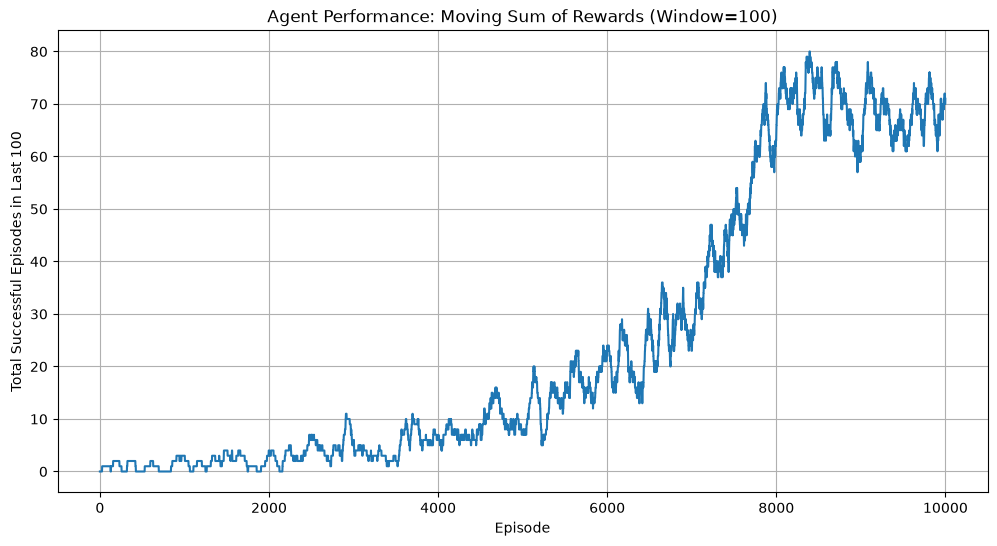

In [5]:
# plotting the moving sum of rewards per episode
sum_rewards = np.zeros(num_episodes)
for x in range(num_episodes):
    sum_rewards[x] = np.sum(reward_per_episode[max(0, x-99):(x+1)])

plt.figure(figsize=(12, 6))
plt.plot(sum_rewards)
plt.title('Agent Performance: Moving Sum of Rewards (Window=100)')
plt.xlabel('Episode')
plt.ylabel('Total Successful Episodes in Last 100')
plt.grid(True)
plt.show()

In [6]:
# Save the learned policy net
policy_filename = 'frozen_lake_dqn_policy.pt'
torch.save(policy_dqn.state_dict(), policy_filename)

print(f"Policy net saved to {policy_filename}")

Policy net saved to frozen_lake_dqn_policy.pt


In [7]:
# open the saved policy net
policy_filename = 'frozen_lake_dqn_policy.pt'

policy_dqn = DQN(num_states=16, num_actions=4)

if os.path.exists(policy_filename):
    policy_dqn.load_state_dict(torch.load(policy_filename))
    policy_dqn.eval() # switch model to evaluation mode
    print(f"Policy net loaded from {policy_filename}")
else:
    print(f"Error: Policy file '{policy_filename}' not found. Please run the training code first.")

Policy net loaded from frozen_lake_dqn_policy.pt


In [8]:
# Evaluate the learned policy
env = gym.make("FrozenLake-v1", is_slippery=True, render_mode='human')

print("Evaluating learned policy...")
total_rewards = 0
num_eval_episodes = 2

for _ in range(num_eval_episodes):
    state, info = env.reset()
    terminated = False # True when agent falls in a hole or reaches the goal
    truncated = False # True when agent takes more than 100 actions
    episode_reward = 0

    while (not terminated and not truncated):
        # For evaluation, use a greedy policy (no exploration)
        with torch.no_grad():
            action = policy_dqn(state_to_dqn_input(state)).argmax().item()

        next_state, reward, terminated, truncated, info = env.step(action)
        episode_reward += reward
        state = next_state

    total_rewards += episode_reward
print(f"Average reward over {num_eval_episodes} evaluation episodes: {total_rewards / num_eval_episodes:.4f}")
env.close()

Evaluating learned policy...
Average reward over 2 evaluation episodes: 0.5000
